#if you've run your own experiments as an extension of the repo, copy this notebook and run it to generate your own visualizations! just upload your result csv files in the third cell

In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

In [2]:
#style stuff
PINK = "#E78FB3"
HOT_PINK = "#C94F91"
LAVENDER = "#B8A1E3"
PURPLE = "#8055B7"
DEEP_PURPLE = "#513477"
PALE_PINK = "#FBEAF2"
PALE_PURPLE = "#F0E9FA"
GREY = "#77717F"
DARK = "#30283A"
WHITE = "#FFFFFF"

plt.rcParams.update({
    "figure.facecolor": WHITE,
    "axes.facecolor": WHITE,
    "axes.edgecolor": "#E5DDE9",
    "axes.labelcolor": DARK,
    "text.color": DARK,
    "xtick.color": GREY,
    "ytick.color": DARK,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "grid.color": "#EEE8F2",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": WHITE,
    "savefig.dpi": 220,
})

def finish_ax(ax, grid_axis="x"):
    ax.set_axisbelow(True)
    ax.grid(axis=grid_axis, alpha=0.9)
    ax.spines["left"].set_color("#E5DDE9")
    ax.spines["bottom"].set_color("#E5DDE9")

def save_fig(fig, filename):
    fig.savefig(filename, bbox_inches="tight", dpi=220)
    plt.show()
    print(f"Saved: {filename}\n")

In [3]:
#loading
print("Upload results_q8.csv and results_q4.csv")
uploaded = files.upload()

def load_csv(filename):
    #Match uploaded filename without depending on letter case.
    matches = [f for f in uploaded if f.lower() == filename.lower()]
    if not matches:
        raise ValueError(
            f"Missing {filename}. Please upload a CSV with that name."
        )
    df = pd.read_csv(io.BytesIO(uploaded[matches[0]]))
    df.columns = df.columns.str.strip().str.lower()
    required = {"target", "prompt", "ttft", "tokens", "tps", "total"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{filename} is missing columns: {missing}")
    return df

q8 = load_csv("results_q8.csv")
q4 = load_csv("results_q4.csv")

for name, df in [("Q8", q8), ("Q4", q4)]:
    for col in ["ttft", "tokens", "tps", "total", "prompt"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df.dropna(subset=["ttft", "tps"], inplace=True)
    print(f"{name}: {len(df)} valid trial rows")

#Keeping loud model labels readable.
def short_name(name):
    if "PHONE" in name.upper():
        return "On-device phone"
    if "dots-studio" in name:
        return "Dots 3 Note"
    if "liquid" in name:
        return "Liquid LFM 2.5"
    if "nemotron" in name:
        return "NVIDIA Nemotron"
    return name.replace(":free", "")

#Q8 is the cloud comparison dataset in the report.
q8["model"] = q8["target"].map(short_name)
q4["model"] = q4["target"].map(short_name)

#Using medians to reduce the influence of individual outlier trials.
summary = (
    q8.groupby("model")
    .agg(
        median_ttft=("ttft", "median"),
        median_tps=("tps", "median"),
        median_total=("total", "median"),
        trials=("prompt", "count")
    )
    .reset_index()
)

print("\nQ8 trial summary:")
display(summary.round(2))


Upload results_q8.csv and results_q4.csv


Saving results_q4.csv to results_q4.csv
Saving results_q8.csv to results_q8.csv
Q8: 12 valid trial rows
Q4: 3 valid trial rows

Q8 trial summary:


,model,median_ttft,median_tps,median_total,trials
0,Dots 3 Note,1.05,59.30,3.93,3
1,Liquid LFM 2.5,0.56,220.55,1.42,3
2,NVIDIA Nemotron,0.55,90.27,3.17,3
3,On-device phone,0.56,15.06,13.76,3


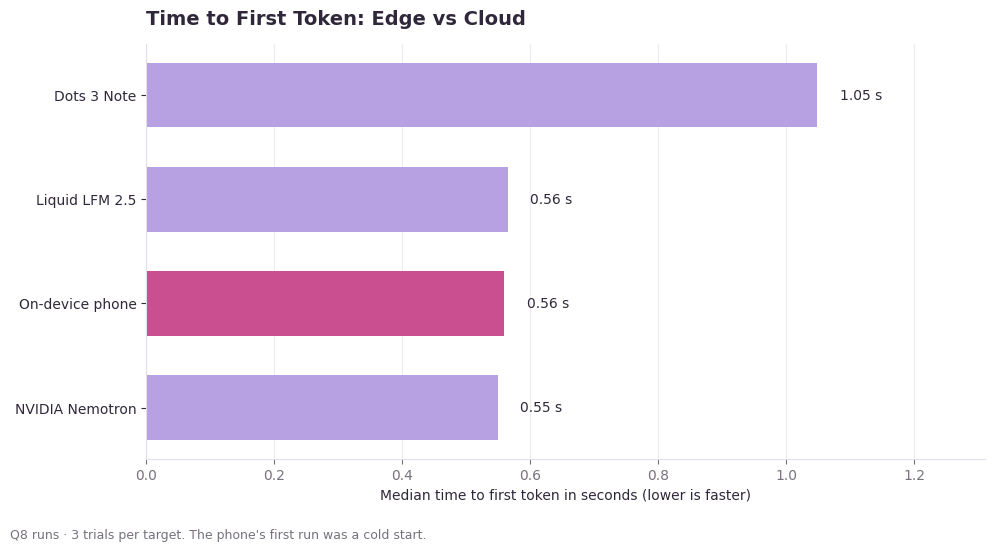

Saved: 01_median_ttft.png



In [5]:
#FIGURE 1: MEDIAN TTFT — PHONE VS CLOUD
order = summary.sort_values("median_ttft")["model"].tolist()
ttft_data = summary.set_index("model").loc[order]

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [
    HOT_PINK if name == "On-device phone" else LAVENDER
    for name in order
]
bars = ax.barh(
    order, ttft_data["median_ttft"],
    color=colors, edgecolor="none", height=0.62
)

for bar, val in zip(bars, ttft_data["median_ttft"]):
    ax.text(
        val + 0.035, bar.get_y() + bar.get_height()/2,
        f"{val:.2f} s", va="center", fontsize=10
    )

ax.set_title("Time to First Token: Edge vs Cloud", loc="left", pad=14)
ax.set_xlabel("Median time to first token in seconds (lower is faster)")
ax.set_xlim(0, max(ttft_data["median_ttft"]) * 1.25)
finish_ax(ax)
fig.text(
    0.01, 0.01,
    "Q8 runs · 3 trials per target. The phone's first run was a cold start.",
    fontsize=9, color=GREY
)
fig.tight_layout(rect=[0, 0.05, 1, 1])
save_fig(fig, "01_median_ttft.png")

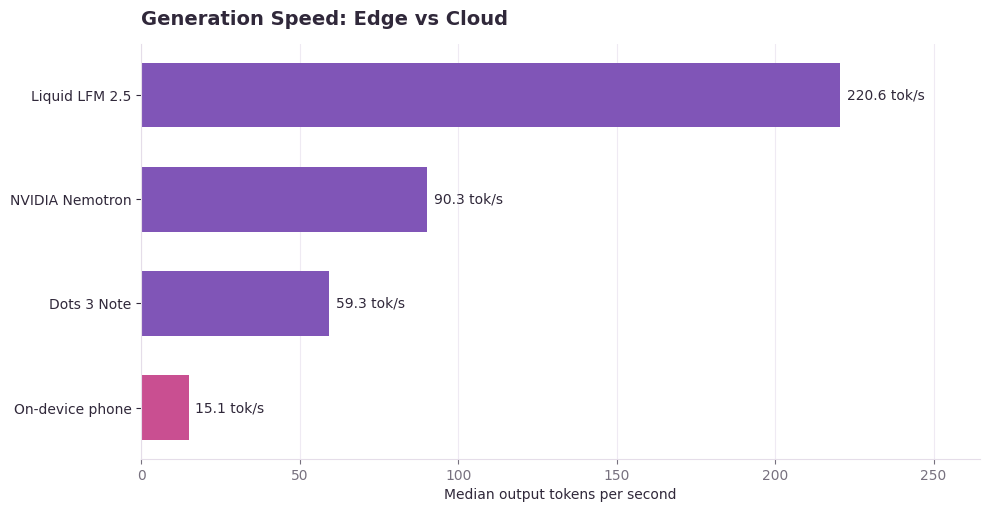

Saved: 02_generation_speed.png



In [9]:
#FIGURE 2: MEDIAN GENERATION SPEED — PHONE VS CLOUD
order = summary.sort_values("median_tps")["model"].tolist()
tps_data = summary.set_index("model").loc[order]

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [
    HOT_PINK if name == "On-device phone" else PURPLE
    for name in order
]
bars = ax.barh(
    order, tps_data["median_tps"],
    color=colors, edgecolor="none", height=0.62
)

for bar, val in zip(bars, tps_data["median_tps"]):
    ax.text(
        val + 2, bar.get_y() + bar.get_height()/2,
        f"{val:.1f} tok/s", va="center", fontsize=10
    )

ax.set_title("Generation Speed: Edge vs Cloud", loc="left", pad=14)
ax.set_xlabel("Median output tokens per second")
ax.set_xlim(0, max(tps_data["median_tps"]) * 1.2)
finish_ax(ax)
fig.tight_layout(rect=[0, 0.05, 1, 1])
save_fig(fig, "02_generation_speed.png")

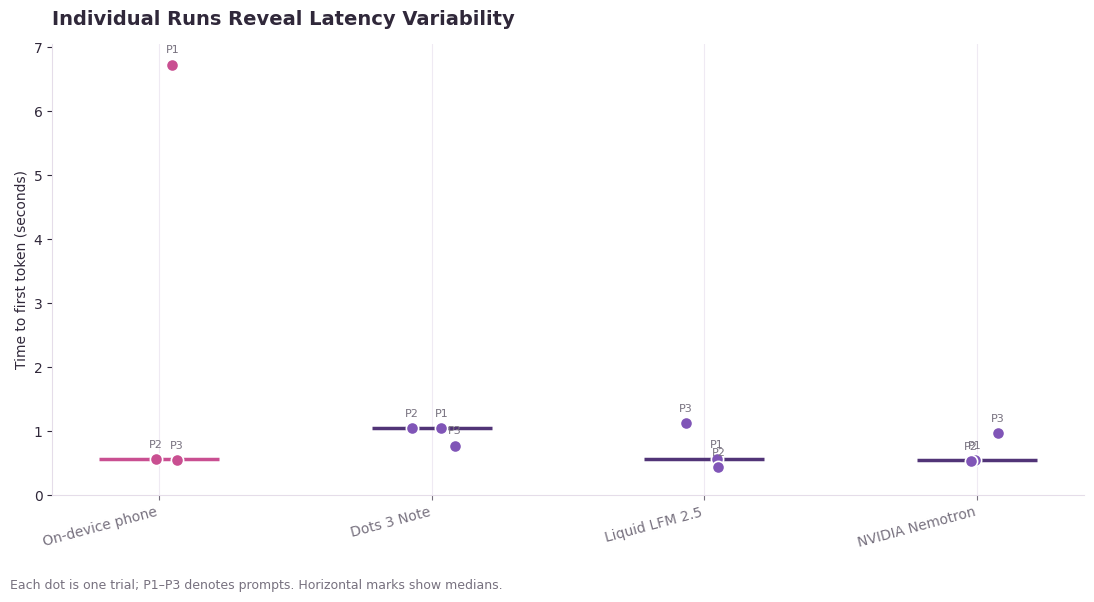

Saved: 03_trial_level_ttft.png



In [10]:
#FIGURE 3: TRIAL-LEVEL TTFT
#(to show cold start and variability hidden by the median)
#Using the original Q8 trials. Each point is one prompt run.
models = q8["model"].drop_duplicates().tolist()
models = sorted(
    models,
    key=lambda m: (m != "On-device phone", m)
)

fig, ax = plt.subplots(figsize=(11, 6))
rng = np.random.default_rng(42)

for i, model in enumerate(models):
    subset = q8[q8["model"] == model]
    x = i + rng.uniform(-0.09, 0.09, len(subset))
    color = HOT_PINK if model == "On-device phone" else PURPLE

    ax.scatter(
        x, subset["ttft"], s=78, color=color,
        edgecolor=WHITE, linewidth=1.2, zorder=3
    )

    median = subset["ttft"].median()
    ax.hlines(
        median, i - 0.22, i + 0.22,
        color=DEEP_PURPLE if model != "On-device phone" else HOT_PINK,
        linewidth=2.5
    )

    for xi, (_, row) in zip(x, subset.iterrows()):
        ax.annotate(
            f"P{int(row['prompt'])}",
            (xi, row["ttft"]),
            xytext=(0, 8), textcoords="offset points",
            ha="center", fontsize=8, color=GREY
        )

ax.set_xticks(range(len(models)))
ax.set_xticklabels(models, rotation=15, ha="right")
ax.set_ylabel("Time to first token (seconds)")
ax.set_title("Individual Runs Reveal Latency Variability", loc="left", pad=14)
ax.set_ylim(bottom=0)
finish_ax(ax)
fig.text(
    0.01, 0.01,
    "Each dot is one trial; P1–P3 denotes prompts. Horizontal marks show medians.",
    fontsize=9, color=GREY
)
fig.tight_layout(rect=[0, 0.05, 1, 1])
save_fig(fig, "03_trial_level_ttft.png")


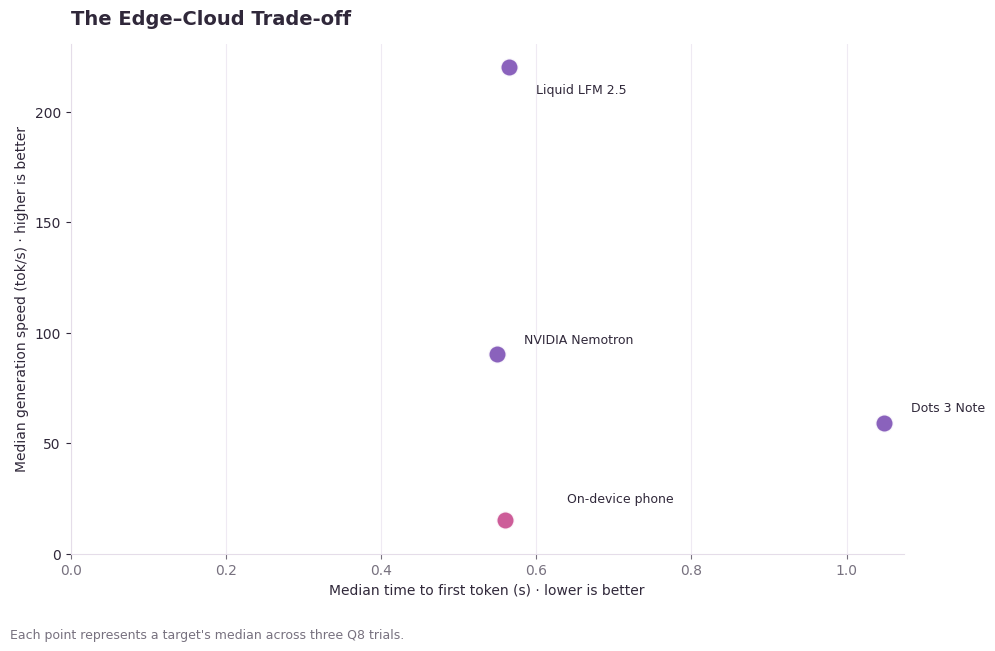

Saved: 04_latency_vs_generation.png



In [12]:
#FIGURE 4: TTFT VS GENERATION SPEED
#(A two-metric view of the edge/cloud trade-off)
fig, ax = plt.subplots(figsize=(10, 6.5))

for _, row in summary.iterrows():
    is_phone = row["model"] == "On-device phone"
    color = HOT_PINK if is_phone else PURPLE

    ax.scatter(
        row["median_ttft"], row["median_tps"],
        s=170, color=color, alpha=0.92,
        edgecolor=WHITE, linewidth=1.5, zorder=3
    )

    # Offset labels to avoid overlap.
    dx = 0.035
    dy = 5 if row["model"] != "Liquid LFM 2.5" else -12
    if is_phone:
        dx, dy = 0.08, 8

    ax.annotate(
        row["model"],
        (row["median_ttft"], row["median_tps"]),
        xytext=(row["median_ttft"] + dx, row["median_tps"] + dy),
        fontsize=9
    )

ax.set_title("The Edge–Cloud Trade-off", loc="left", pad=14)
ax.set_xlabel("Median time to first token (s) · lower is better")
ax.set_ylabel("Median generation speed (tok/s) · higher is better")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
finish_ax(ax)
fig.text(
    0.01, 0.01,
    "Each point represents a target's median across three Q8 trials. ",
    fontsize=9, color=GREY
)
fig.tight_layout(rect=[0, 0.05, 1, 1])
save_fig(fig, "04_latency_vs_generation.png")


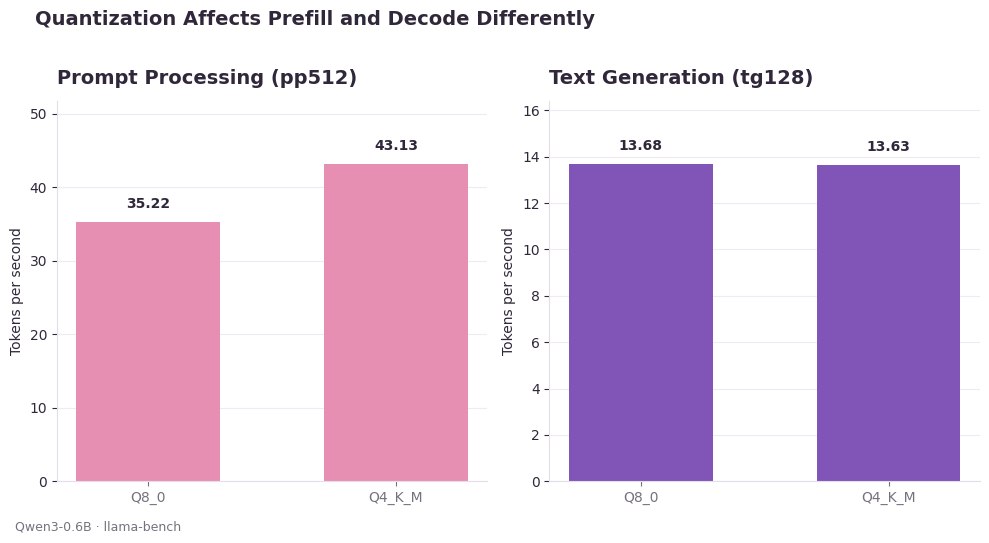

Saved: 05_quantization_tradeoffs.png



In [15]:
#FIGURE 5:  QUANTIZATION — PREFILL VS DECODE
#llama-bench results from the learning report of my project, replace this with your numbers
quant = pd.DataFrame({
    "Model": ["Q8_0", "Q4_K_M"],
    "Prompt Processing": [35.22, 43.13],
    "Text Generation": [13.68, 13.63],
})

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

charts = [
    (axes[0], "Prompt Processing", "pp512", PINK),
    (axes[1], "Text Generation", "tg128", PURPLE),
]

for ax, column, benchmark, color in charts:
    values = quant[column]

    bars = ax.bar(
        quant["Model"],
        values,
        color=color,
        width=0.58,
        edgecolor="none",
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(values) * 0.035,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

    ax.set_title(f"{column} ({benchmark})", pad=12, loc="left")
    ax.set_ylabel("Tokens per second")
    ax.set_ylim(0, max(values) * 1.2)
    finish_ax(ax, grid_axis="y")

fig.suptitle(
    "Quantization Affects Prefill and Decode Differently",
    x=0.04,
    ha="left",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.02, -0.02,
    "Qwen3-0.6B · llama-bench",
    fontsize=9,
    color=GREY,
)

fig.tight_layout()
save_fig(fig, "05_quantization_tradeoffs.png")

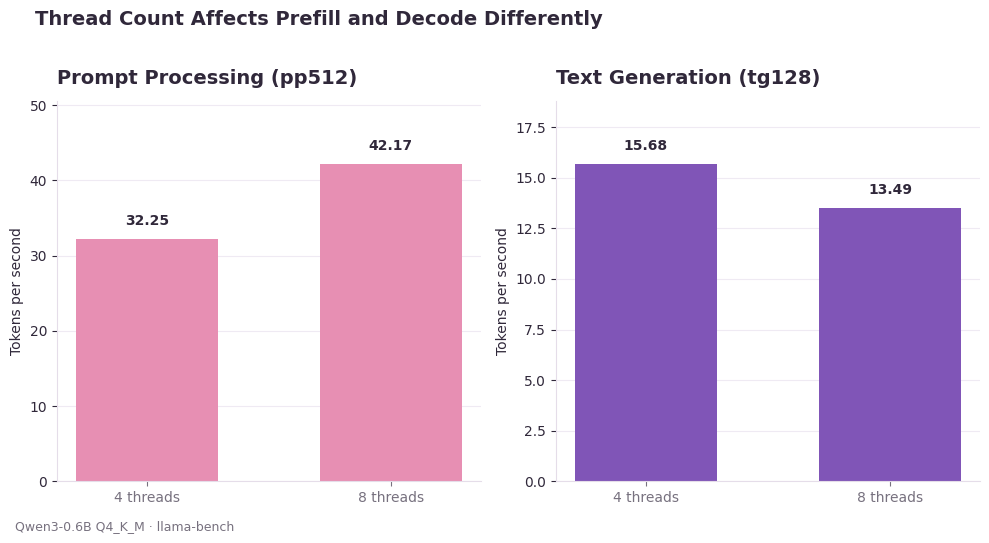

Saved: 06_thread_count.png



In [17]:
#FIGURE 6 - THREAD COUNT
threads = pd.DataFrame({
    "Threads": ["4 threads", "8 threads"],
    "Prefill": [32.25, 42.17],
    "Decode": [15.68, 13.49],
})

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

charts = [
    (axes[0], "Prefill", "Prompt Processing (pp512)", PINK),
    (axes[1], "Decode", "Text Generation (tg128)", PURPLE),
]

for ax, column, title, color in charts:
    values = threads[column]

    bars = ax.bar(
        threads["Threads"],
        values,
        color=color,
        width=0.58,
        edgecolor="none",
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(values) * 0.035,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

    ax.set_title(title, pad=12, loc="left")
    ax.set_ylabel("Tokens per second")
    ax.set_ylim(0, max(values) * 1.2)
    finish_ax(ax, grid_axis="y")

fig.suptitle(
    "Thread Count Affects Prefill and Decode Differently",
    x=0.04,
    ha="left",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.02, -0.02,
    "Qwen3-0.6B Q4_K_M · llama-bench",
    fontsize=9,
    color=GREY,
)

fig.tight_layout()
save_fig(fig, "06_thread_count.png")